In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import descr

In [16]:
from scipy.stats import kendalltau, spearmanr
from scipy.stats import rankdata

In [17]:
p_mean, p_var = np.load("p_scores/p_mean.npy"), np.load("p_scores/p_var.npy")

In [18]:
sigma_row = np.load("p_scores/rank_flip_sigma_row.npy")

In [19]:
p_mean.shape, p_var.shape

((130802,), (130802,))

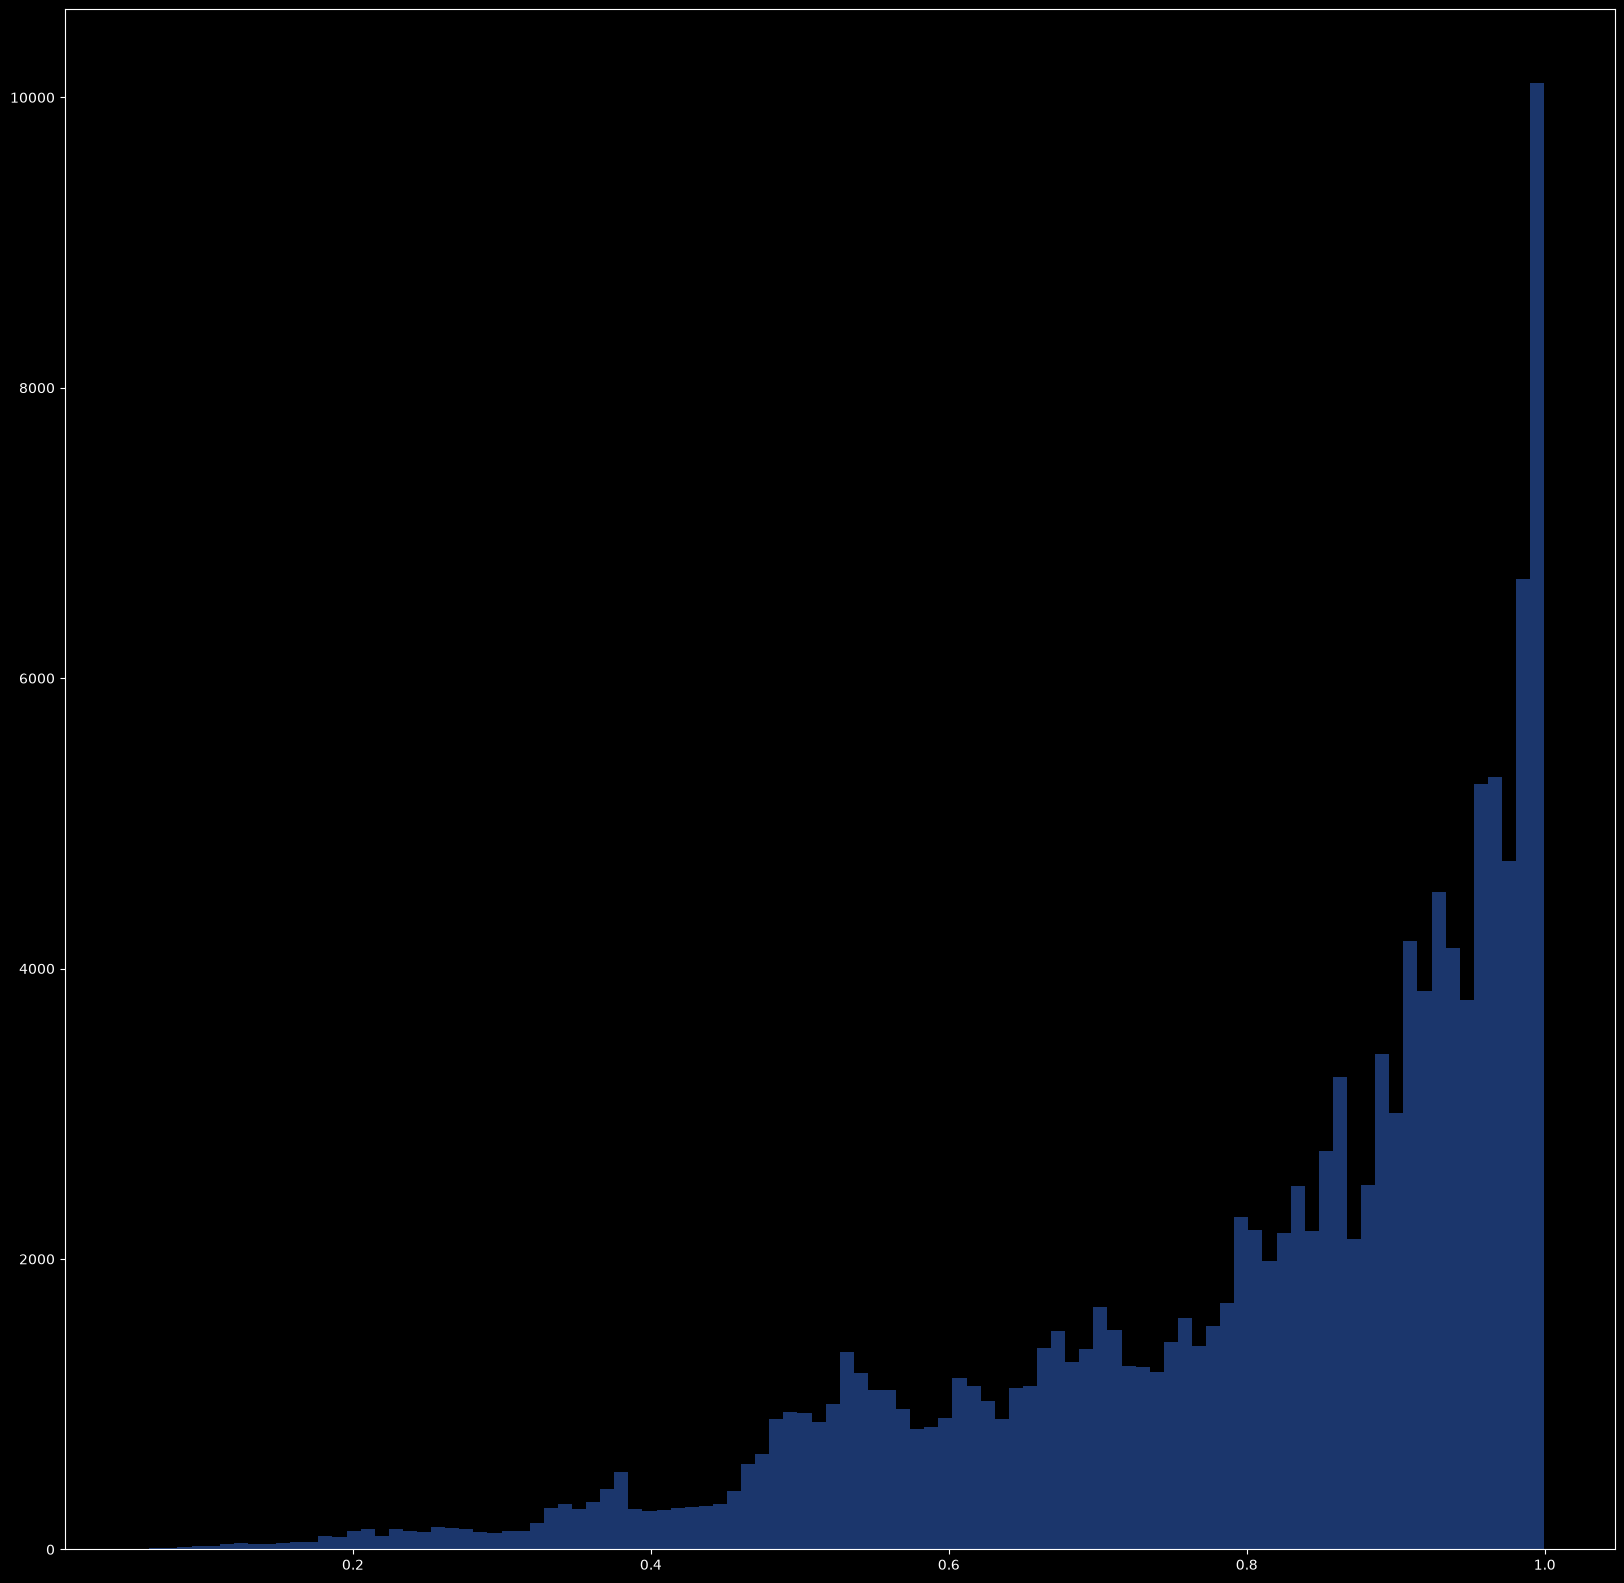

In [20]:
plt.figure(figsize=(20,20))
plt.hist(sigma_row.flatten(), bins=100, alpha=0.5)
plt.show()

In [21]:
sigma_row.mean(), 4*sigma_row.var()

(np.float64(0.8032492208714728), np.float64(0.13378212840602588))

In [22]:
mean_ranking = rankdata(-p_mean, method='min')
var_ranking = rankdata(-p_var, method='min')

In [23]:
kendalltau(mean_ranking, var_ranking)

SignificanceResult(statistic=np.float64(0.09084347783853582), pvalue=np.float64(0.0))

In [24]:
spearmanr(mean_ranking, var_ranking)

SignificanceResult(statistic=np.float64(0.10235799762208826), pvalue=np.float64(1.5206598823934945e-301))

In [25]:
np.abs(var_ranking - mean_ranking).max()

np.float64(130721.0)

In [26]:
np.abs(var_ranking - mean_ranking).argmax()

np.int64(112738)

In [27]:
p_mean[112738], p_var[112738]

(np.float64(0.8032416701316833), np.float64(0.13380178809165955))